# MURA Baseline Model
## Frozen ResNet-18 Feature Extraction + Logistic Regression

**Objective:** Establish a reproducible baseline for study-level
normal/abnormal classification of MURA wrist radiographs.

**Data strategy:**
- Internal train: 2,769 studies
- Internal validation: 691 studies
- Official MURA validation: locked final test set

**Important:** No patient overlap between internal training and validation.

## Step 1 — Load and Verify the Internal Datasets

### Objective
Load the MURA wrist training and internal validation datasets prepared in Notebook 01 and verify their integrity before baseline model development.

### Methodology
- Connect Google Colab to Google Drive.
- Define the paths to the original MURA ZIP archive and the saved dataset manifests.
- Load `wrist_internal_train.csv` and `wrist_internal_val.csv`.
- Verify image counts, available metadata, and class distributions.
- Confirm that the original ZIP archive is accessible.

### Dataset Summary

| Dataset | Normal Images | Abnormal Images | Total Images | Studies |
|---|---:|---:|---:|---:|
| Internal Training | 4,631 | 3,179 | 7,810 | 2,769 |
| Internal Validation | 1,138 | 808 | 1,946 | 691 |
| **Total** | **5,769** | **3,987** | **9,756** | **3,460** |

The internal datasets were generated using a patient-level split in Notebook 01. Verification confirmed zero patient overlap and zero study overlap between the two datasets.

### Expected Outcome
Both datasets are loaded successfully, with correct image counts, labels, and metadata.

**Data separation:** The official MURA validation dataset remains locked and is excluded from baseline training and threshold selection.

In [21]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

DRIVE_ROOT = Path('/content/drive/MyDrive')

print("✓ Google Drive mounted")
print("Drive root exists:", DRIVE_ROOT.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Google Drive mounted
Drive root exists: True


## Step 2 — Verify Image Paths in the MURA ZIP Archive

### Objective
Confirm that every wrist X-ray image referenced in the internal training and validation manifests exists in the original MURA ZIP archive.

### Methodology
- Open `MURA-v1.1_files.zip` using Python's `zipfile` library.
- Inspect the archive's internal directory structure.
- Detect whether image paths require an additional directory prefix.
- Compare all image paths in the training and validation CSV files against the ZIP archive entries.
- Identify missing or incorrectly referenced images before feature extraction.

### Verification Results

| Check | Result |
|---|---|
| Total ZIP entries | 40,013 |
| Detected ZIP path prefix | Empty (`""`) |
| Training images verified | 7,810 |
| Validation images verified | 1,946 |
| Missing training images | 0 |
| Missing validation images | 0 |

### Outcome
**Verification PASSED:** All 9,756 internal wrist images were successfully matched to entries in the MURA ZIP archive.

The images can therefore be loaded directly from the compressed archive without extracting or duplicating the complete dataset.

### Next Stage
Initialize the ImageNet-pretrained ResNet-18 model and prepare it as a frozen feature extractor for the Logistic Regression baseline.

In [22]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path(
    "/content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA"
)

# Corrected path construction by appending string-based subpaths to DATA_DIR
SPLIT_DIR = DATA_DIR / "WRIST_SPLITS"

# Dynamically locate the zip file under the data directory to avoid hardcoding errors
zip_files = list(DATA_DIR.rglob("*.zip"))
if zip_files:
    ZIP_PATH = zip_files[0]
else:
    ZIP_PATH = DATA_DIR / "MURA-v1.1.zip"

# Load internal training and validation
train_df = pd.read_csv(
    SPLIT_DIR / "wrist_internal_train.csv"
)

val_df = pd.read_csv(
    SPLIT_DIR / "wrist_internal_val.csv"
)

print("=== BASELINE DATA VERIFICATION ===")
print("Located ZIP Path:", ZIP_PATH)
print("ZIP exists:", ZIP_PATH.is_file())
print("Split folder exists:", SPLIT_DIR.is_dir())

print("\nTraining images:", len(train_df))
print("Validation images:", len(val_df))

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nTraining labels:")
print(train_df["label"].value_counts())

print("\nValidation labels:")
print(val_df["label"].value_counts())

print("\nExample image path:")
print(train_df["file_name"].iloc[0])

assert ZIP_PATH.is_file(), f"MURA ZIP not found at {ZIP_PATH}"
assert len(train_df) == 7810
assert len(val_df) == 1946

print("\n✓ Dataset manifests loaded successfully")

=== BASELINE DATA VERIFICATION ===
Located ZIP Path: /content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/MURA-v1.1_files.zip
ZIP exists: True
Split folder exists: True

Training images: 7810
Validation images: 1946

Training columns:
['file_id', 'file_name', 'size', 'added_at', 'md5_hash', 'file_extension', 'patient_id', 'study_id', 'label', 'study_uid']

Training labels:
label
negative    4631
positive    3179
Name: count, dtype: int64

Validation labels:
label
negative    1138
positive     808
Name: count, dtype: int64

Example image path:
train/XR_WRIST/patient08997/study1_negative/image2.png

✓ Dataset manifests loaded successfully


In [23]:
import zipfile

print("=== ZIP CONTENT VERIFICATION ===")

with zipfile.ZipFile(ZIP_PATH, "r") as zf:

    zip_files = set(zf.namelist())

    print("Total ZIP entries:", len(zip_files))

    print("\nFirst 5 entries:")
    for name in list(zf.namelist())[:5]:
        print(" ", name)

    # Determine the path prefix
    example = train_df["file_name"].iloc[0].lstrip("/")

    if example in zip_files:
        ZIP_PREFIX = ""
    elif f"MURA-v1.1/{example}" in zip_files:
        ZIP_PREFIX = "MURA-v1.1/"
    else:
        raise FileNotFoundError(
            f"Example image not found in ZIP: {example}"
        )

    print("\nDetected ZIP prefix:", repr(ZIP_PREFIX))

    # Verify all training and validation images
    def check_paths(df):
        paths = (
            ZIP_PREFIX
            + df["file_name"].astype(str).str.lstrip("/")
        )
        missing = [p for p in paths if p not in zip_files]
        return missing

    missing_train = check_paths(train_df)
    missing_val = check_paths(val_df)

    print("\nMissing training images:", len(missing_train))
    print("Missing validation images:", len(missing_val))

    assert len(missing_train) == 0, "Training images missing"
    assert len(missing_val) == 0, "Validation images missing"

print("\n✓ All 9,756 wrist images verified in ZIP")

=== ZIP CONTENT VERIFICATION ===
Total ZIP entries: 40013

First 5 entries:
  valid/XR_WRIST/patient11185/study1_positive/image1.png
  valid/XR_SHOULDER/patient11798/study1_negative/image2.png
  valid/XR_SHOULDER/patient11735/study1_positive/image1.png
  valid/XR_WRIST/patient11385/study1_negative/image3.png
  valid/XR_WRIST/patient11235/study1_positive/image5.png

Detected ZIP prefix: ''

Missing training images: 0
Missing validation images: 0

✓ All 9,756 wrist images verified in ZIP



## Step 3 - Prepare PyTorch and the Pretrained ResNet-18

Our baseline model will use:

- **ResNet-18:** An ImageNet-pretrained convolutional neural network that extracts 512 features from each wrist X-ray image.
- **Frozen weights:** The pretrained ResNet-18 parameters will remain unchanged during baseline development.
- **Logistic Regression:** A separate binary classifier trained on the extracted image features to predict normal versus abnormal.
- **Study-level evaluation:** Image-level abnormality probabilities will be aggregated across all images belonging to the same study.

**Objective:** Establish a reproducible baseline for comparison with the fine-tuned ResNet-18 model.
  

Using the pretrained weights' preprocessing ensures that the grayscale X-rays, converted to RGB for ResNet-18, receive the expected input normalization.
A methodological note: These are ImageNet-pretrained features, not features specifically trained for radiology. That is appropriate for our baseline, and later we will compare them with a fine-tuned ResNet-18.

In [24]:
import torch
import torch.nn as nn
import torchvision

from torchvision import models, transforms
from PIL import Image
from torch.utils.data import Dataset, DataLoader

import numpy as np
import pandas as pd
import zipfile
import io

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
Device: cuda
GPU: Tesla T4


In [25]:
# Load ImageNet-pretrained ResNet-18
weights = models.ResNet18_Weights.DEFAULT

resnet18 = models.resnet18(weights=weights)

# Freeze all model parameters
for param in resnet18.parameters():
    param.requires_grad = False

# Remove the final classification layer
# ResNet-18 now outputs 512 features per image
resnet18.fc = nn.Identity()

# Move to GPU/CPU and enable inference mode
resnet18 = resnet18.to(DEVICE)
resnet18.eval()

# Use preprocessing associated with pretrained weights
preprocess = weights.transforms()

print("Feature extractor ready")
print("Output feature dimension:", 512)
print(
    "Trainable parameters:",
    sum(p.numel() for p in resnet18.parameters()
        if p.requires_grad)
)

Feature extractor ready
Output feature dimension: 512
Trainable parameters: 0



## Step 4 — Create the MURA Wrist Dataset

**Objective:** Implement a custom PyTorch Dataset that reads wrist X-ray images directly from the MURA ZIP archive.

**Methodology:**
- Load image paths and labels from the saved internal training and validation CSV files.
- Read PNG images directly from the ZIP archive.
- Convert grayscale images to three-channel RGB for compatibility with ImageNet-pretrained ResNet-18.
- Apply the pretrained ResNet-18 preprocessing transformations.
- Preserve patient and study identifiers for subsequent study-level aggregation.

**Expected output:** A validated Dataset and DataLoader for extracting 512-dimensional image features.


In [33]:
import os
import io
import zipfile
from PIL import Image
from torch.utils.data import Dataset

class MURAWristDataset(Dataset):
    def __init__(self, dataframe, zip_path, transform):
        self.df = dataframe.reset_index(drop=True).copy()
        self.zip_path = str(zip_path)
        self.transform = transform

        # Use a dictionary to map process IDs to their respective zipfile handles
        self._zips = {}

        self.df["label_binary"] = self.df["label"].map({
            "negative": 0,
            "positive": 1
        })
        assert self.df["label_binary"].notna().all(), "Unexpected labels in dataset"

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        pid = os.getpid()
        if pid not in self._zips:
            self._zips[pid] = zipfile.ZipFile(self.zip_path, "r")

        zf = self._zips[pid]
        row = self.df.iloc[idx]
        image_path = ZIP_PREFIX + row["file_name"].lstrip("/")

        image_bytes = zf.read(image_path)

        with Image.open(io.BytesIO(image_bytes)) as img:
            image = img.convert("RGB")

        image = self.transform(image)
        label = int(row["label_binary"])

        return image, label, idx

    def __del__(self):
        for zf in getattr(self, "_zips", {}).values():
            try:
                zf.close()
            except Exception:
                pass

print("✓ MURAWristDataset class updated with __len__ method and process-safe zip handling")

✓ MURAWristDataset class updated with __len__ method and process-safe zip handling


In [34]:
BATCH_SIZE = 32

train_dataset = MURAWristDataset(
    dataframe=train_df,
    zip_path=ZIP_PATH,
    transform=preprocess
)

val_dataset = MURAWristDataset(
    dataframe=val_df,
    zip_path=ZIP_PATH,
    transform=preprocess
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("=== DATASET CONFIGURATION ===")
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

=== DATASET CONFIGURATION ===
Training images: 7810
Validation images: 1946
Batch size: 32
Training batches: 245
Validation batches: 61


In [35]:
images, labels, indices = next(iter(train_loader))

print("=== FIRST BATCH CHECK ===")
print("Image tensor shape:", images.shape)
print("Label tensor shape:", labels.shape)
print("First 5 indices:", indices[:5].tolist())
print("First 5 labels:", labels[:5].tolist())

assert images.shape == (32, 3, 224, 224)
assert labels.shape == (32,)
assert torch.isfinite(images).all()

print("\n✓ First batch loaded and validated successfully")

=== FIRST BATCH CHECK ===
Image tensor shape: torch.Size([32, 3, 224, 224])
Label tensor shape: torch.Size([32])
First 5 indices: [0, 1, 2, 3, 4]
First 5 labels: [0, 0, 0, 0, 0]

✓ First batch loaded and validated successfully



## Step 5 — Extract and Save ResNet-18 Image Features

### Objective
Generate 512-dimensional feature representations for all MURA wrist images using the frozen ImageNet-pretrained ResNet-18 model.

### Methodology
- Process internal training and validation images in batches.
- Perform inference with ResNet-18 in evaluation mode.
- Disable gradient computation to reduce memory consumption.
- Preserve the original image order to maintain alignment with labels and study identifiers.
- Save feature matrices to Google Drive for reproducible baseline classification.

### Expected Output
- Training features: `(7810, 512)`
- Validation features: `(1946, 512)`
- Saved NumPy feature arrays for subsequent Logistic Regression training.

**Data integrity:** The official MURA validation set is excluded from this stage.


In [36]:
from tqdm.auto import tqdm
import numpy as np
import torch

def extract_features(model, loader, device, description):

    model.eval()

    all_features = []
    all_labels = []
    all_indices = []

    with torch.inference_mode():

        for images, labels, indices in tqdm(
            loader, desc=description
        ):

            images = images.to(device, non_blocking=True)

            features = model(images)

            all_features.append(
                features.cpu().numpy()
            )

            all_labels.append(
                labels.numpy()
            )

            all_indices.append(
                indices.numpy()
            )

    X = np.concatenate(all_features, axis=0)
    y = np.concatenate(all_labels, axis=0)
    indices = np.concatenate(all_indices, axis=0)

    # Restore original dataframe order
    order = np.argsort(indices)

    X = X[order]
    y = y[order]
    indices = indices[order]

    assert np.array_equal(
        indices, np.arange(len(loader.dataset))
    ), "Image indices do not match dataset order"

    assert X.shape[1] == 512
    assert np.isfinite(X).all()

    print(f"\n{description} complete")
    print("Feature matrix:", X.shape)
    print("Labels:", y.shape)

    return X, y

In [37]:
X_train, y_train = extract_features(
    model=resnet18,
    loader=train_loader,
    device=DEVICE,
    description="Training feature extraction"
)

X_val, y_val = extract_features(
    model=resnet18,
    loader=val_loader,
    device=DEVICE,
    description="Validation feature extraction"
)

assert X_train.shape == (7810, 512)
assert X_val.shape == (1946, 512)

assert np.array_equal(
    y_train,
    train_df["label"].map(
        {"negative": 0, "positive": 1}
    ).to_numpy()
)

assert np.array_equal(
    y_val,
    val_df["label"].map(
        {"negative": 0, "positive": 1}
    ).to_numpy()
)

print("\n✓ Feature extraction and label alignment verified")

Training feature extraction:   0%|          | 0/245 [00:00<?, ?it/s]


Training feature extraction complete
Feature matrix: (7810, 512)
Labels: (7810,)


Validation feature extraction:   0%|          | 0/61 [00:00<?, ?it/s]

UnidentifiedImageError: Caught UnidentifiedImageError in DataLoader worker process 0.
Original Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/worker.py", line 358, in _worker_loop
    data = fetcher.fetch(index)  # type: ignore[possibly-undefined]
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/fetch.py", line 54, in fetch
    data = [self.dataset[idx] for idx in possibly_batched_index]
            ~~~~~~~~~~~~^^^^^
  File "/tmp/ipykernel_1252/990152603.py", line 36, in __getitem__
    with Image.open(io.BytesIO(image_bytes)) as img:
         ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/Image.py", line 3580, in open
    raise UnidentifiedImageError(msg)
PIL.UnidentifiedImageError: cannot identify image file <_io.BytesIO object at 0x7937d4d29da0>


In [38]:
from PIL import Image, UnidentifiedImageError
import zipfile
import io

print("=== VALIDATION IMAGE INTEGRITY CHECK ===")

bad_images = []

with zipfile.ZipFile(ZIP_PATH, "r") as zf:

    for idx, row in val_df.iterrows():

        image_path = ZIP_PREFIX + row["file_name"].lstrip("/")

        try:
            image_bytes = zf.read(image_path)

            with Image.open(io.BytesIO(image_bytes)) as img:
                img.load()

        except Exception as e:
            bad_images.append({
                "index": idx,
                "path": image_path,
                "error": str(e)
            })

print("Images checked:", len(val_df))
print("Problematic images:", len(bad_images))

for item in bad_images[:20]:
    print(item)

=== VALIDATION IMAGE INTEGRITY CHECK ===
Images checked: 1946
Problematic images: 4
{'index': 262, 'path': 'train/XR_WRIST/patient07840/study1_negative/._image1.png', 'error': 'cannot identify image file <_io.BytesIO object at 0x7937f6b108b0>'}
{'index': 559, 'path': 'train/XR_WRIST/patient07840/study2_negative/._image3.png', 'error': 'cannot identify image file <_io.BytesIO object at 0x7937f6b108b0>'}
{'index': 679, 'path': 'train/XR_WRIST/patient07840/study2_negative/._image1.png', 'error': 'cannot identify image file <_io.BytesIO object at 0x7937f4786430>'}
{'index': 1325, 'path': 'train/XR_WRIST/patient07840/study2_negative/._image2.png', 'error': 'cannot identify image file <_io.BytesIO object at 0x7937f6aca660>'}


In [39]:
print("=== APPLEDOUBLE METADATA CHECK ===")

for name, df in [
    ("Training", train_df),
    ("Validation", val_df)
]:
    metadata_mask = (
        df["file_name"]
        .str.split("/")
        .str[-1]
        .str.startswith("._")
    )

    print(f"\n{name}:")
    print("Total entries:", len(df))
    print("AppleDouble files:", metadata_mask.sum())

    if metadata_mask.any():
        print(
            df.loc[metadata_mask, "file_name"]
            .to_string(index=False)
        )

=== APPLEDOUBLE METADATA CHECK ===

Training:
Total entries: 7810
AppleDouble files: 0

Validation:
Total entries: 1946
AppleDouble files: 4
train/XR_WRIST/patient07840/study1_negative/._i...
train/XR_WRIST/patient07840/study2_negative/._i...
train/XR_WRIST/patient07840/study2_negative/._i...
train/XR_WRIST/patient07840/study2_negative/._i...


In [40]:
# Remove AppleDouble metadata entries from validation
metadata_mask = (
    val_df["file_name"]
    .str.split("/")
    .str[-1]
    .str.startswith("._")
)

val_df_clean = (
    val_df.loc[~metadata_mask]
    .reset_index(drop=True)
    .copy()
)

print("=== VALIDATION DATA CLEANING ===")
print("Original entries:", len(val_df))
print("Metadata files removed:", metadata_mask.sum())
print("Clean validation images:", len(val_df_clean))

print("\nValidation studies:", val_df_clean["study_uid"].nunique())
print("Validation patients:", val_df_clean["patient_id"].nunique())

assert len(val_df_clean) == 1942
assert val_df_clean["study_uid"].nunique() == 691
assert val_df_clean["patient_id"].nunique() == 653

print("\n✓ Validation metadata cleaning verified")

=== VALIDATION DATA CLEANING ===
Original entries: 1946
Metadata files removed: 4
Clean validation images: 1942

Validation studies: 691
Validation patients: 653

✓ Validation metadata cleaning verified


In [41]:
val_dataset = MURAWristDataset(
    dataframe=val_df_clean,
    zip_path=ZIP_PATH,
    transform=preprocess
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Validation images:", len(val_dataset))
print("Validation batches:", len(val_loader))

Validation images: 1942
Validation batches: 61


In [42]:
X_val, y_val = extract_features(
    model=resnet18,
    loader=val_loader,
    device=DEVICE,
    description="Clean validation feature extraction"
)

# Verify dimensions
assert X_val.shape == (1942, 512)
assert y_val.shape == (1942,)

# Verify alignment with the cleaned manifest
expected_labels = val_df_clean["label"].map({
    "negative": 0,
    "positive": 1
}).to_numpy()

assert np.array_equal(y_val, expected_labels)
assert np.isfinite(X_val).all()

print("\n✓ Validation feature extraction successful")
print("Feature matrix:", X_val.shape)
print("Labels:", y_val.shape)

Clean validation feature extraction:   0%|          | 0/61 [00:00<?, ?it/s]


Clean validation feature extraction complete
Feature matrix: (1942, 512)
Labels: (1942,)

✓ Validation feature extraction successful
Feature matrix: (1942, 512)
Labels: (1942,)


Both datasets now have their ResNet-18 features extracted successfully.
Dataset	Feature matrix	Status
Internal training	7,810 × 512	Complete
Internal validation	1,942 × 512	Complete
We can now save the results permanently to Google Drive before moving to Logistic Regression.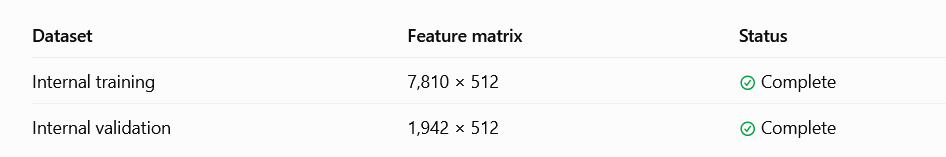


### Step 5H — Save Extracted Features and Cleaned Validation Data

**Objective:** Preserve the extracted ResNet-18 feature matrices, corresponding labels, and cleaned validation manifest for reproducible baseline model development.

**Methodology:**
- Save training and validation features as NumPy arrays.
- Preserve the original ordering of images and labels.
- Save the cleaned validation manifest separately from the original.
- Verify that all saved files can be reloaded successfully.

**Expected output:** Four NumPy files and one cleaned CSV manifest stored permanently in Google Drive.


In [43]:
from pathlib import Path
import numpy as np
import pandas as pd

FEATURE_DIR = DATA_DIR / "baseline_features"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

# Verify alignment before saving
assert X_train.shape == (7810, 512)
assert y_train.shape == (7810,)
assert X_val.shape == (1942, 512)
assert y_val.shape == (1942,)

assert np.array_equal(
    y_train,
    train_df["label"].map({"negative": 0, "positive": 1}).to_numpy()
)

assert np.array_equal(
    y_val,
    val_df_clean["label"].map({"negative": 0, "positive": 1}).to_numpy()
)

# Save extracted features and labels
np.save(FEATURE_DIR / "X_train_resnet18.npy", X_train)
np.save(FEATURE_DIR / "y_train.npy", y_train)

np.save(FEATURE_DIR / "X_val_resnet18.npy", X_val)
np.save(FEATURE_DIR / "y_val.npy", y_val)

# Save cleaned validation manifest
val_df_clean.to_csv(
    SPLIT_DIR / "wrist_internal_val_clean.csv",
    index=False
)

print("=== SAVED BASELINE FEATURES ===")

for file in sorted(FEATURE_DIR.glob("*.npy")):
    print(
        file.name,
        f"({file.stat().st_size / 1024**2:.2f} MB)"
    )

print("\nClean validation manifest saved.")

=== SAVED BASELINE FEATURES ===
X_train_resnet18.npy (15.25 MB)
X_val_resnet18.npy (3.79 MB)
y_train.npy (0.06 MB)
y_val.npy (0.01 MB)

Clean validation manifest saved.


In [44]:
X_train_check = np.load(FEATURE_DIR / "X_train_resnet18.npy")
X_val_check = np.load(FEATURE_DIR / "X_val_resnet18.npy")

y_train_check = np.load(FEATURE_DIR / "y_train.npy")
y_val_check = np.load(FEATURE_DIR / "y_val.npy")

saved_val_df = pd.read_csv(
    SPLIT_DIR / "wrist_internal_val_clean.csv"
)

assert X_train_check.shape == (7810, 512)
assert X_val_check.shape == (1942, 512)

assert np.array_equal(y_train_check, y_train)
assert np.array_equal(y_val_check, y_val)

assert len(saved_val_df) == 1942
assert saved_val_df["study_uid"].nunique() == 691

print("✓ All saved files reloaded successfully")
print("✓ Feature dimensions and labels verified")
print("✓ Validation studies preserved")

✓ All saved files reloaded successfully
✓ Feature dimensions and labels verified
✓ Validation studies preserved



## Step 6 — Train the Logistic Regression Baseline

### Objective
Train a binary Logistic Regression classifier using 512-dimensional image features extracted by frozen ImageNet-pretrained ResNet-18.

### Methodology
- Train Logistic Regression using internal training data only.
- Use standardized features to improve numerical optimization.
- Predict abnormality probabilities for internal validation images.
- Aggregate image-level probabilities by study using their mean.
- Evaluate study-level discrimination using AUROC.
- Select a decision threshold using internal validation studies, targeting sensitivity ≥95%.

### Data Separation
- **Internal training:** 7,810 images from 2,769 studies.
- **Internal validation:** 1,942 images from 691 studies.
- **Official validation:** Locked final test set, excluded from model development.

### Expected Output
A trained Logistic Regression baseline producing study-level probabilities for normal versus abnormal classification.


In [45]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import numpy as np

# Create baseline pipeline
baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        C=1.0,
        solver="lbfgs",
        random_state=42
    ))
])

# Train using internal training images only
baseline.fit(X_train, y_train)

print("=== LOGISTIC REGRESSION BASELINE ===")
print("Training completed successfully")

# Predict probabilities for internal validation images
val_probabilities = baseline.predict_proba(X_val)[:, 1]

assert len(val_probabilities) == 1942
assert np.isfinite(val_probabilities).all()
assert np.all((val_probabilities >= 0) & (val_probabilities <= 1))

print("Validation predictions:", len(val_probabilities))
print("Probability range:",
      round(val_probabilities.min(), 4),
      "to",
      round(val_probabilities.max(), 4))

print("\n✓ Baseline model trained successfully")

=== LOGISTIC REGRESSION BASELINE ===
Training completed successfully
Validation predictions: 1942
Probability range: 0.0001 to 0.9999

✓ Baseline model trained successfully


In [46]:
# Combine predictions with validation metadata
val_results = val_df_clean[
    ["patient_id", "study_uid", "label", "file_name"]
].copy()

val_results["probability"] = val_probabilities

# Aggregate image predictions into study-level predictions
study_results = (
    val_results
    .groupby("study_uid", as_index=False)
    .agg(
        patient_id=("patient_id", "first"),
        label=("label", "first"),
        study_probability=("probability", "mean"),
        image_count=("file_name", "count")
    )
)

study_results["label_binary"] = (
    study_results["label"]
    .map({"negative": 0, "positive": 1})
)

assert len(study_results) == 691
assert study_results["label_binary"].notna().all()

study_auc = roc_auc_score(
    study_results["label_binary"],
    study_results["study_probability"]
)

print("=== STUDY-LEVEL BASELINE RESULTS ===")
print("Studies evaluated:", len(study_results))
print("Study-level AUROC:", round(study_auc, 4))
print("\nFirst 5 study predictions:")
print(study_results.head().to_string(index=False))

=== STUDY-LEVEL BASELINE RESULTS ===
Studies evaluated: 691
Study-level AUROC: 0.8892

First 5 study predictions:
                   study_uid   patient_id    label  study_probability  image_count  label_binary
patient00012/study1_negative patient00012 negative           0.596411            4             0
patient00077/study1_positive patient00077 positive           0.850196            3             1
patient00147/study1_positive patient00147 positive           0.962181            4             1
patient00147/study2_negative patient00147 negative           0.318356            2             0
patient00148/study1_negative patient00148 negative           0.076672            1             0
